# DASC8412 Assignment 2: Question 3

**Student Number:** ST10365068

### Validation Framework

To decide what to check in the dataset, this notebook follows the six data quality dimensions recommended by the Data Management Association UK and published by the Government Data Quality Hub (2021). Each dimension asks a different question about the data:

1. **Validity:** do the values follow the required format, type and allowed range?
2. **Uniqueness:** does each school appear only once?
3. **Completeness:** is all of the data needed for the analysis present?
4. **Consistency:** do the values agree with each other within and across records?
5. **Accuracy:** do the values correctly describe the real schools?
6. **Timeliness:** is the data current enough to be used for planning?

Every check below is linked to one of these dimensions so that the findings can be used directly in the answers to Questions 3.2 and 3.3. All checks are performed on the raw data before any cleaning, so the results show the true condition of the dataset as it was supplied.

## 1. Import Libraries

In [1]:
# ST10365068
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

### Libraries

This code block imports the libraries needed for the validation. The csv module is used to read the file line by line, pandas is used to store and inspect the data in a DataFrame, numpy supports numerical checks, and matplotlib and seaborn are used to create the charts. The display options make sure that pandas shows every column when a table is printed.

## 2. Structural Validity: Attempting a Standard Load

The first validity check is whether the file can be read correctly with the standard pandas read_csv function. A well formed CSV file should load into separate columns with no extra steps.

In [2]:
# ST10365068
# first attempt using the default settings
try:
    df_test = pd.read_csv('School_Data_CSV.csv')
except Exception as e:
    print('Default load failed:')
    print(type(e).__name__, ':', e)

Default load failed:
UnicodeDecodeError : 'utf-8' codec can't decode byte 0xeb in position 8313: invalid continuation byte


### Encoding Error

The default load fails with a UnicodeDecodeError. This means the file is not saved in the UTF8 encoding that pandas expects. Some school names and addresses contain special characters, such as the letter ë in Afrikaans names, which are stored in an older Latin encoding. This is the first sign that the file was not prepared to a consistent standard.

In [3]:
# ST10365068
# second attempt using the Latin encoding and skipping rows that cannot be read
df_test = pd.read_csv('School_Data_CSV.csv', encoding='latin-1', on_bad_lines='skip', low_memory=False)

print('Shape:', df_test.shape)
print()
print('Column names:')
print(df_test.columns.tolist())
print()
print('Number of non null values in each column:')
print(df_test.notnull().sum())

Shape: (199852, 9)

Column names:
['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat;;;;']

Number of non null values in each column:
emisno              199852
centername           32662
institution_name     32978
centreno             37335
quintile             36575
ward_id              36910
street_address       30653
new_long             24731
new_lat;;;;          37316
dtype: int64


### Column Structure Error

With the Latin encoding the file loads, but the result is wrong. The last column name is shown as "new_lat;;;;", which means the header line ends with four stray semicolons. The count of non null values shows that almost every value has been pushed into the first column, emisno, while the other columns are nearly empty. This happens because most rows are wrapped in one pair of quotation marks, so pandas reads the whole row as a single value. The file therefore fails the validity check at the most basic level, because its structure does not match the CSV format.

In [4]:
# ST10365068
# look at the raw text of the first few lines to see the problem directly
with open('School_Data_CSV.csv', encoding='latin-1') as f:
    raw_lines = f.read().splitlines()

print('Total lines in file (including header):', len(raw_lines))
print()
for line in raw_lines[:4]:
    print(line)

Total lines in file (including header): 199854

emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat;;;;
"200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,""10 PARLIAMENT STREET,  ABERDEEN, 6270"",24.06183,-32.47385";;;;
"200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,""WELSH STREET, ADELAIDE, 5760"",26.29476,-32.71036";;;;
"200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,""PERSEVERANCE DR, SOMERSET EAST, 5850"",25.60073,-32.74592";;;;


### Raw File Inspection

Printing the raw lines confirms the problem. Each data row starts and ends with a quotation mark and is followed by four semicolons. Inside each row, the street address is wrapped in doubled quotation marks because it contains commas. The file has 199,854 lines, which means there are 199,853 data rows below the header.

## 3. Loading the Data Correctly

Because the standard load does not work, the file is read line by line. The extra semicolons and the outer quotation marks are removed from each row, and the remaining text is then split into fields with the csv module.

In [5]:
# ST10365068
header = raw_lines[0].rstrip(';').split(',')

parsed_rows = []
for line in raw_lines[1:]:
    line = line.rstrip(';')
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1].replace('""', '"')
    parsed_rows.append(next(csv.reader([line])))

field_counts = pd.Series([len(r) for r in parsed_rows]).value_counts().sort_index()
print('Column names:', header)
print()
print('Number of fields found in each row:')
print(field_counts)

Column names: ['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat']

Number of fields found in each row:
9     199835
10         1
11         7
12         8
13         2
Name: count, dtype: int64


### Row Length Check

After the formatting is removed, the header contains the nine expected column names. Almost every row splits into exactly nine fields, as it should. However, 18 rows split into 10, 11, 12 or 13 fields. These rows have addresses that contain extra semicolons and quotation marks, which break the row into too many pieces. Because their values cannot be matched to the correct columns with confidence, they are set aside and the analysis continues with the rows that have nine fields.

In [6]:
# ST10365068
bad_rows = [r for r in parsed_rows if len(r) != len(header)]
print('Example of a broken row:')
print(bad_rows[0])
print()

df = pd.DataFrame([r for r in parsed_rows if len(r) == len(header)], columns=header)
df = df.apply(lambda col: col.str.strip())

print('Rows set aside:', len(bad_rows))
print('Shape of the working dataset:', df.shape)
df.head()

Example of a broken row:
['700400452', 'WATERSHED TECHNICAL SCHOOL', 'WATERSHED TECHNICAL SCHOOL', '8400452', 'NA', '79800124', '130 MARSHAL STREET, 7TH FLOOR;" INTEC HOUSE', ' MARSHALLTOWN', ' 2000"', '28.04458', 'NA']



Rows set aside: 18
Shape of the working dataset: (199835, 9)


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


### Working Dataset

The example of a broken row shows an address for a school in Marshalltown that contains a semicolon and a stray quotation mark, which split the address across several columns. After removing the 18 broken rows, the working dataset contains 199,835 rows and 9 columns. The first five rows now display correctly, with each value in its proper column. Extra spaces at the start and end of each value have also been removed so that the checks below are not affected by spacing.

In [7]:
# ST10365068
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 199835 entries, 0 to 199834
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   emisno            199835 non-null  str  
 1   centername        199835 non-null  str  
 2   institution_name  199835 non-null  str  
 3   centreno          199835 non-null  str  
 4   quintile          199835 non-null  str  
 5   ward_id           199835 non-null  str  
 6   street_address    199835 non-null  str  
 7   new_long          199835 non-null  str  
 8   new_lat           199835 non-null  str  
dtypes: str(9)
memory usage: 13.7 MB


### Data Types

The info output shows that all nine columns are stored as text. Pandas reports no null values at all. This is misleading, because, as the next section shows, the file uses text labels such as "NA" and "TO BE UPDATED" instead of true empty cells. The numeric columns new_long and new_lat are also stored as text because they contain these labels, so they cannot be used for calculations without validation.

## 4. Uniqueness

Each school in South Africa has a unique EMIS number, so in a clean dataset each EMIS number should appear only once. This section checks for exact duplicate rows and for schools that appear more than once.

In [8]:
# ST10365068
exact_duplicates = df.duplicated().sum()
unique_schools = df['emisno'].nunique()

print('Total rows:', len(df))
print('Exact duplicate rows:', exact_duplicates)
print('Unique EMIS numbers:', unique_schools)
print('Average rows per school:', round(len(df) / unique_schools, 2))
print('EMIS numbers that appear more than once:', (df['emisno'].value_counts() > 1).sum())
print()
print('Most repeated EMIS numbers:')
print(df['emisno'].value_counts().head(5))

Total rows: 199835
Exact duplicate rows: 799
Unique EMIS numbers: 33668
Average rows per school: 5.94
EMIS numbers that appear more than once: 31899

Most repeated EMIS numbers:
emisno
99           1549
MKHUHLU        14
200500824      12
600101176      12
200100037      11
Name: count, dtype: int64


### Duplicate Findings

The dataset contains 199,835 rows but only 33,668 unique EMIS numbers, which means each school appears about six times on average. There are 799 rows that are exact copies of another row. The most repeated EMIS number is "99", which appears 1,549 times. This is clearly a placeholder value rather than a real school number. The dataset has no year column, so it is not possible to tell whether the repeated rows are yearly snapshots of the same school or simple capture errors. If these rows were counted as separate schools, the number of schools would be greatly overstated.

## 5. Completeness

Completeness checks whether the values needed for the analysis are present. Because pandas reported no nulls, this check searches for the text labels that the file uses in place of missing values.

In [9]:
# ST10365068
placeholders = ['NA', 'N/A', 'NOT APPLICABLE', 'TO BE UPDATED', 'NULL', 'UNKNOWN', 'TBU', '.', '']

missing_table = pd.DataFrame({
    col: [(df[col].str.upper() == p).sum() for p in placeholders] for col in df.columns
}, index=[f"'{p}'" for p in placeholders]).T

missing_table['Total hidden missing'] = missing_table.sum(axis=1)
missing_table['Percent missing'] = (missing_table['Total hidden missing'] / len(df) * 100).round(1)
missing_table

,'NA','N/A','NOT APPLICABLE','TO BE UPDATED','NULL','UNKNOWN','TBU','.','',Total hidden missing,Percent missing
emisno,0,0,0,0,0,0,0,0,0,0,0.0
centername,1,5815,90055,8251,114,0,4,35643,0,139883,70.0
institution_name,65920,0,0,0,0,0,0,1,0,65921,33.0
centreno,25,0,17704,0,0,0,3,27893,5,45630,22.8
quintile,2521,260,16042,22328,0,9,0,936,30,42126,21.1
ward_id,752,0,0,12072,0,0,0,3481,30,16335,8.2
street_address,6638,0,0,130,32,706,8,1760,33,9307,4.7
new_long,32045,0,0,0,0,0,0,1578,66,33689,16.9
new_lat,115673,0,0,0,0,0,0,0,66,115739,57.9


### Hidden Missing Values

The table shows that missing information is recorded in at least nine different ways, including "NA", "N/A", "NOT APPLICABLE", "TO BE UPDATED", "NULL", "UNKNOWN", a single full stop and a blank cell. None of these labels is recognised by pandas as missing, which is why the info output reported no nulls. The latitude column (new_lat) is the most incomplete, with about 58% of rows missing a value. Longitude is missing in about 17% of rows and the quintile in about 21%, with 22,328 rows still marked "TO BE UPDATED". The school name columns also contain many placeholders.

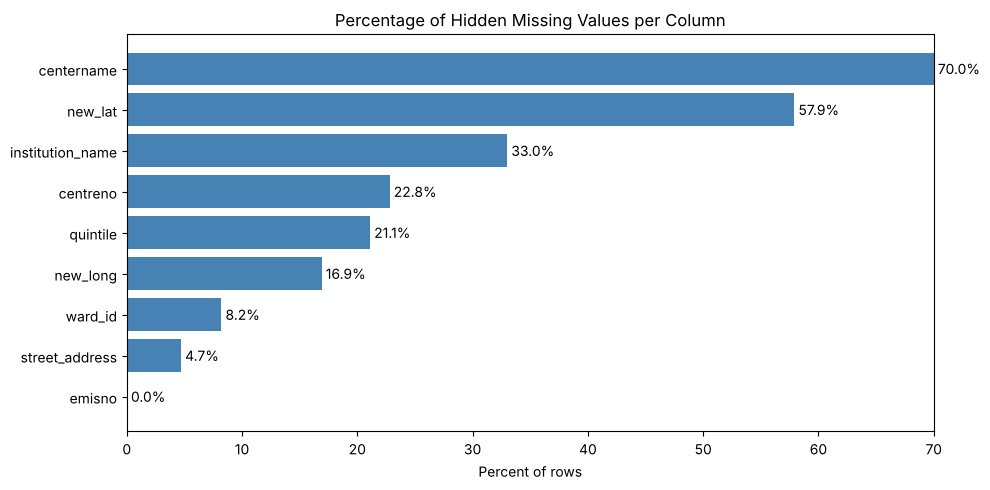

In [10]:
# ST10365068
plot_data = missing_table['Percent missing'].sort_values()

plt.figure(figsize=(10, 5))
bars = plt.barh(plot_data.index, plot_data.values, color='steelblue')
plt.bar_label(bars, fmt='%.1f%%', padding=3)
plt.title('Percentage of Hidden Missing Values per Column')
plt.xlabel('Percent of rows')
plt.xlim(0, 70)
plt.tight_layout()
plt.show()

### Missing Values Chart

The bar chart shows the percentage of hidden missing values in each column. It makes clear that the location fields, which are essential for planning where new schools should be built, are among the least complete. Latitude is missing far more often than longitude, which also means that many rows have one coordinate but not the other, so the location of those schools cannot be plotted at all.

## 6. Consistency

Consistency checks whether the same information is recorded in the same way across the dataset. The quintile column is used as the main example because the quintile decides a school's funding level and no fee status.

In [11]:
# ST10365068
print('All values found in the quintile column:')
print(df['quintile'].value_counts())

All values found in the quintile column:
quintile
1                                                    49010
2                                                    40109
3                                                    32288
TO BE UPDATED                                        22298
NOT APPLICABLE                                       16042
5                                                    12916
4                                                    11428
Q1                                                    3760
Q2                                                    3211
Q3                                                    2961
NA                                                    2521
.                                                      936
Q4                                                     879
Q5                                                     835
NQ2                                                    281
N/A                                                    260
      

### Quintile Categories

A school's quintile should be one of five values, from 1 to 5. Instead, the column contains 26 different values. The same quintile is written in different ways, for example "1", "Q1" and "NQ1" all refer to quintile 1. The column also contains values that do not belong there at all, including the number 99, a coordinate (27.19015) and a full street address. These suggest that some values were captured in the wrong columns.

In [12]:
# ST10365068
quintile_per_school = df.groupby('emisno')['quintile'].nunique()
latitude_per_school = df.groupby('emisno')['new_lat'].nunique()

print('Schools with more than one quintile value:', (quintile_per_school > 1).sum())
print('Schools with more than one latitude value:', (latitude_per_school > 1).sum())
print()

print('Example of one school with conflicting records:')
df[df['emisno'] == '100000029'][['emisno', 'institution_name', 'quintile', 'new_long', 'new_lat']]

Schools with more than one quintile value: 22946
Schools with more than one latitude value: 25821

Example of one school with conflicting records:


,emisno,institution_name,quintile,new_long,new_lat
2270,100000029,GAIA WALDORF SCHOOL,4,18.489704,NA
27051,100000029,GAIA WALDORF SCHOOL,4,18.489704,NA
34158,100000029,GAIA WALDORF SCHOOL,4,18.489704,NA
61920,100000029,GAIA WALDORF SCHOOL,TO BE UPDATED,18.489704,NA
110867,100000029,NA,NOT APPLICABLE,18.489704,-33.940894
138983,100000029,NA,TO BE UPDATED,18.489704,-33.940894
176868,100000029,GAIA WALDORF SCHOOL,5,18.489704,NA


### Conflicting Records

Because each school appears several times, its repeated rows can be compared. This check finds 22,946 schools with more than one quintile value and 25,821 schools with more than one latitude value. The example table shows Gaia Waldorf School, which appears seven times. Its quintile is recorded as 4 in some rows, 5 in another, and "TO BE UPDATED" or "NOT APPLICABLE" in others. Its latitude is present in only two rows, and in those same rows its name is missing. When the records for the same school contradict each other, an analyst cannot tell which value is correct without going back to the source.

## 7. Validity of Values

Validity checks whether each value has the correct type and falls within an allowed range. South Africa lies roughly between longitude 16 and 33 degrees east and latitude 22 and 35 degrees south, so any school coordinate outside this box must be wrong.

In [13]:
# ST10365068
lon = pd.to_numeric(df['new_long'], errors='coerce')
lat = pd.to_numeric(df['new_lat'], errors='coerce')

both_present = lon.notna() & lat.notna()
inside_sa = lon.between(16, 33) & lat.between(-35, -22)
outside_sa = both_present & ~inside_sa

print('Longitude values that are not numbers:', lon.isna().sum())
print('Latitude values that are not numbers:', lat.isna().sum())
print('Rows with coordinates equal to zero:', ((lon == 0) | (lat == 0)).sum())
print('Rows with both coordinates present:', both_present.sum())
print('Rows with coordinates outside South Africa:', outside_sa.sum())
print()
df[outside_sa][['emisno', 'institution_name', 'new_long', 'new_lat']].head(8)

Longitude values that are not numbers: 39371
Latitude values that are not numbers: 115739
Rows with coordinates equal to zero: 40
Rows with both coordinates present: 84094
Rows with coordinates outside South Africa: 15



,emisno,institution_name,new_long,new_lat
81212,600977,NA,0,0
81574,404035,NA,0,0
92965,400525,NA,2812528.031,-25.417032
95995,500327707,NA,30.370237,-29609503
98578,500400562,NA,30.83418,-29815809
98784,500321937,NA,31.580706,-29026399
103790,996602106,NA,29.85093765,-21.84173988
106012,800031401,NA,22.938126,-30556799


### Coordinate Range Check

Converting the coordinates to numbers shows that 39,371 longitude values and 115,739 latitude values are not valid numbers. There are 40 rows with a coordinate of zero, which would place a school in the Atlantic Ocean off the coast of West Africa. A further group of schools have coordinates that fall outside South Africa. The table shows examples such as a latitude of minus 29,609,503 and a longitude of 2,812,528, which appear to be correct values that lost their decimal point during capture.

In [14]:
# ST10365068
print('Length of EMIS numbers:')
print(df['emisno'].str.len().value_counts())
print()
print('EMIS numbers that contain letters:', (~df['emisno'].str.isdigit()).sum())
print()
print('Length of ward_id values:')
print(df['ward_id'].str.len().value_counts())

Length of EMIS numbers:


emisno
9     197299
2       1549
6        911
5         45
7         18
11         4
3          3
8          3
4          2
12         1
Name: count, dtype: int64

EMIS numbers that contain letters: 33

Length of ward_id values:
ward_id
8     163728
2      14168
13     12072
1       9821
0         30
3         15
9          1
Name: count, dtype: int64


### Identifier Format Check

A valid EMIS number in this dataset has nine digits. Most rows meet this rule, but 1,549 rows use the two digit placeholder "99" and others have 5, 6, 7 or 11 characters. There are 33 EMIS numbers that contain letters, such as "MKHUHLU", which is a place name rather than an identifier. The ward_id column should hold an eight digit ward code, but it also contains one and two digit numbers and 12,072 values of thirteen characters, which is the length of the text "TO BE UPDATED". These identifiers cannot be reliably joined to other government data, such as census figures by ward.

## 8. Accuracy

Accuracy asks whether the data correctly describes the real world. A practical way to test this for location data is to plot every valid coordinate. If the coordinates are accurate, the points should form the shape of South Africa.

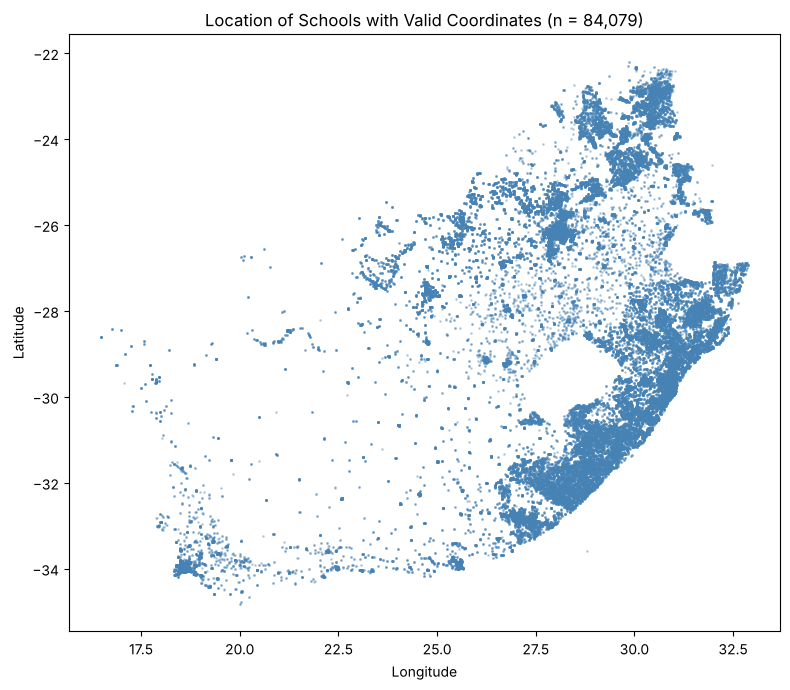

In [15]:
# ST10365068
plot_df = pd.DataFrame({'lon': lon, 'lat': lat})[inside_sa]

plt.figure(figsize=(8, 7))
plt.scatter(plot_df['lon'], plot_df['lat'], s=1, alpha=0.3, color='steelblue')
plt.title(f'Location of Schools with Valid Coordinates (n = {len(plot_df):,})')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

### Location Plot

The scatter plot shows that the rows with valid coordinates do form the outline of South Africa, with dense clusters in Gauteng, KwaZulu Natal and the Eastern Cape. The empty area near longitude 28 and latitude minus 29.5 is Lesotho, which is a separate country, so its absence is another sign that these coordinates are correct. This means the coordinates that pass validation are broadly accurate. However, only 84,079 rows have both coordinates inside South Africa, out of 199,835 rows in total. Any map built from this dataset would therefore leave out more than half of the records, and provinces with weaker record keeping would appear to have fewer schools than they really do.

## 9. Timeliness

Timeliness asks whether the data is current enough for its purpose. For school planning, officials need to know which schools are open now.

In [16]:
# ST10365068
print('Columns in the dataset:')
print(df.columns.tolist())
print()
date_columns = [c for c in df.columns if any(w in c.lower() for w in ['year', 'date', 'time', 'status'])]
print('Columns that record a date, year or school status:', date_columns if date_columns else 'None')

Columns in the dataset:
['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat']

Columns that record a date, year or school status: None


### Missing Time Information

The dataset has no column for the year of the record, the date it was last updated, or whether a school is open or closed. This is a serious timeliness problem for this case study. FEDSAS reports that more than 650 schools have closed in the Eastern Cape since 2009 (FEDSAS, 2024), but this dataset gives no way to tell which of its schools are still operating. The "TO BE UPDATED" labels found earlier also show that many records were never completed.

## 10. Summary of Data Quality Issues

In [17]:
# ST10365068
valid_quintile = df['quintile'].str.upper().str.replace(r'^N?Q', '', regex=True).isin(['1', '2', '3', '4', '5'])
usable = valid_quintile & inside_sa

summary = pd.DataFrame({
    'Dimension': ['Validity', 'Validity', 'Uniqueness', 'Uniqueness', 'Completeness', 'Completeness',
                  'Consistency', 'Consistency', 'Validity', 'Accuracy', 'Timeliness'],
    'Issue found': ['Rows with the wrong number of fields',
                    'File encoding and quotation errors',
                    'Exact duplicate rows',
                    'Rows using the placeholder EMIS number 99',
                    'Rows with latitude missing',
                    'Rows with quintile marked TO BE UPDATED',
                    'Different quintile values found',
                    'Schools with conflicting quintile values',
                    'Coordinates equal to zero',
                    'Rows with both coordinates inside South Africa',
                    'Columns that record a year or school status'],
    'Count': [len(bad_rows),
              'Whole file',
              exact_duplicates,
              (df['emisno'] == '99').sum(),
              (df['new_lat'].str.upper().isin(placeholders)).sum(),
              (df['quintile'].str.upper() == 'TO BE UPDATED').sum(),
              df['quintile'].nunique(),
              (quintile_per_school > 1).sum(),
              ((lon == 0) | (lat == 0)).sum(),
              inside_sa.sum(),
              0]
})

print('Rows with a valid quintile AND valid coordinates:', usable.sum(),
      f'({usable.mean() * 100:.1f}% of the dataset)')
summary

Rows with a valid quintile AND valid coordinates: 62378 (31.2% of the dataset)


,Dimension,Issue found,Count
0,Validity,Rows with the wrong number of fields,18
1,Validity,File encoding and quotation errors,Whole file
2,Uniqueness,Exact duplicate rows,799
3,Uniqueness,Rows using the placeholder EMIS number 99,1549
4,Completeness,Rows with latitude missing,115739
5,Completeness,Rows with quintile marked TO BE UPDATED,22328
6,Consistency,Different quintile values found,26
7,Consistency,Schools with conflicting quintile values,22946
8,Validity,Coordinates equal to zero,40
9,Accuracy,Rows with both coordinates inside South Africa,84079


### Overall Finding

The summary table brings together the issues found under each of the six data quality dimensions. Only 62,378 rows, about 31% of the dataset, have both a valid quintile and coordinates inside South Africa. This means that roughly two out of every three records would need to be corrected, completed or removed before the dataset could be trusted for funding or school planning decisions. This supports the warning in the case study that departmental data from some periods and regions may still be inaccurate (FEDSAS, 2024), and it shows why validation must happen before any analysis is carried out.

## References

Combrink, H., Carr, E., de Wet, K., Marivate, V. and Rosman, B. (2023) *South Africa Education Data and Visualisations*. University of the Free State. Available at: https://doi.org/10.38140/ufs.22081058.v4 [Accessed 13 October 2026].

FEDSAS (2024) *FEDSAS's 'Education in numbers' report: These are some of the most important tendencies in SA education*. Federation of Governing Bodies of South African Schools, 4 December. Available at: https://www.fedsas.org.za/Media/Article/fedsas-s-education-in-numbers-report-these-are-some-of-the-most-important-tendencies-in-sa-education-202412041111 [Accessed 13 October 2026].

Government Data Quality Hub (2021) *Meet the data quality dimensions*. GOV.UK, 24 June. Available at: https://www.gov.uk/government/news/meet-the-data-quality-dimensions [Accessed 13 October 2026].